# OpenFOAM Farassat 1A showcase

This notebook reads OpenFOAM `p` and `U` surface files, inspects the parsed geometry and fields, and evaluates the stationary permeable-surface Farassat 1A formulation.

## Scope

The formulation assumes fixed surface velocity $v_S=0$, zero mean-flow convection $U_0=0$, constant density, kinematic OpenFOAM pressure, and adjustable source time steps.

In [1]:
import importlib
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
from tqdm import tqdm
import torch

from foamacoustics import F1ASolver
from foamacoustics import OpenFOAMSurfaceSeries
from foamacoustics.plotting import (
    plot_oaspl_directivity,
    plot_pressure_history,
    plot_spl_spectrum,
)
from foamacoustics.utils import spl_spectrum_to_oaspl, spl_spectrum_to_a_weighted_oaspl

importlib.import_module("scienceplots")
plt.style.use(["science", "no-latex"])

/home/dpusino/FoamAcoustics/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
surface_vtk_dir = Path(r"../cylinder15r")
surface_file = "Cylx15.vtk"
pressure_field = "p"
velocity_field = "U"
pressure_units = "kinematic"
density_kg_m3 = 1.225
pressure_reference_pa = 0.0

# Acoustic propagation settings
sound_speed_m_s = 343.0
response_delay_s = 1.0e-5
adjust_time_step = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
numerical_dtype = torch.float32
observer_radius_m = 1.88
observer_angles_deg = torch.arange(
    90.0, -91.0, -10.0, device=device, dtype=numerical_dtype
)
observer_angles_rad = torch.deg2rad(observer_angles_deg)
observers_m = observer_radius_m * torch.stack(
    (
        torch.cos(observer_angles_rad),
        torch.sin(observer_angles_rad),
        torch.zeros_like(observer_angles_rad),
    ),
    dim=1,
)
rpm = 7000.0  # Used only for duration/BPF context; the control surface stays fixed.

vtk_read_workers = 10
binary_cache_dir = (
    Path(".cache") / f"cylinder15r_{str(numerical_dtype).removeprefix('torch.')}"
)
invalid_time_policy = "interpolate"
print(f"Using device: {device}")
chunk_size = 64

Using device: cuda


## 1. Parse the OpenFOAM surface series

Geometry is reconstructed once from the first legacy VTK file. Every later file is checked against its geometry/topology fingerprint and yields only one `p` array and one three-component `U` array. Numeric directory names define the source-time order.

In [3]:
series = OpenFOAMSurfaceSeries(
    surface_vtk_dir,
    surface_file=surface_file,
    pressure_field=pressure_field,
    velocity_field=velocity_field,
    pressure_units=pressure_units,
    density_kg_m3=density_kg_m3,
    pressure_reference_pa=pressure_reference_pa,
    dtype=numerical_dtype,
    cache_dir=binary_cache_dir,
)

if not series.cache_enabled:
    cache_progress = tqdm(total=len(series), desc="Building binary cache", unit="frame")

    def report_cache_progress(done, total, message):
        cache_progress.update(done - cache_progress.n)
        if done == total:
            cache_progress.close()

    series.build_cache(
        workers=vtk_read_workers,
        invalid_time_policy=invalid_time_policy,
        progress_callback=report_cache_progress,
    )
print(f"Binary cache: {binary_cache_dir.resolve()} (active={series.cache_enabled})")

frame_iterator = series.iter_frames(workers=vtk_read_workers)
first_frame = next(frame_iterator)
second_frame = next(frame_iterator)
del frame_iterator
assert first_frame.pressure_pa.shape == (series.panel_count,)
assert first_frame.fluid_velocity_m_s.shape == (series.panel_count, 3)
assert first_frame.pressure_pa.dtype == numerical_dtype
assert first_frame.fluid_velocity_m_s.dtype == numerical_dtype
assert torch.isfinite(first_frame.pressure_pa).all()
assert torch.isfinite(first_frame.fluid_velocity_m_s).all()

time_steps_s = torch.diff(series.absolute_times_s)
area_closure_ratio = (
    torch.linalg.vector_norm(series.outward_area_vectors_m2.sum(dim=0))
    / series.face_areas_m2.sum()
)
triangle_mesh = series.polygons.numel() == 4 * series.panel_count and torch.all(
    series.polygons[::4] == 3
)

print(f"Root: {surface_vtk_dir.resolve()}")
print(
    f"Frames: {len(series):,} from {series.time_names[0]} to {series.time_names[-1]} s"
)
print(f"Duration: {series.source_times_s[-1]:.9f} s")
print(f"Time-step range: {time_steps_s.min():.9g} to {time_steps_s.max():.9g} s")
print(f"Faces: {series.panel_count:,}; triangle-only mesh: {triangle_mesh}")
print(f"Total surface area: {series.face_areas_m2.sum():.9g} m^2")
print(f"Oriented-area closure ratio: {area_closure_ratio:.3e}")
print(f"Geometry fingerprint: {series.geometry_fingerprint.hex()}")
print(f"Field dtype: {series.dtype}; p scale to Pa: {series.pressure_scale_to_pa:g}")
print(
    f"p shape: {first_frame.pressure_pa.shape}; U shape: {first_frame.fluid_velocity_m_s.shape}"
)
print(
    "First-frame p range: "
    f"{first_frame.pressure_pa.min():.6g} to {first_frame.pressure_pa.max():.6g} Pa"
)
print(
    "Maximum change in the next frame: "
    f"|dp|={torch.max(torch.abs(second_frame.pressure_pa - first_frame.pressure_pa)):.6g} Pa, "
    f"|dU|={torch.max(torch.linalg.vector_norm(second_frame.fluid_velocity_m_s - first_frame.fluid_velocity_m_s, dim=1)):.6g} m/s"
)

Binary cache: /home/dpusino/FoamAcoustics/.cache/cylinder15r_float32 (active=True)
Root: /home/dpusino/cylinder15r
Frames: 20,001 from 0.1 to 0.2 s
Duration: 0.100000000 s
Time-step range: 5e-06 to 5e-06 s
Faces: 38,880; triangle-only mesh: True
Total surface area: 0.467375557 m^2
Oriented-area closure ratio: 3.683e-16
Geometry fingerprint: 64d13bf93f5c44682d75c8bf9a458400
Field dtype: torch.float32; p scale to Pa: 1.225
p shape: torch.Size([38880]); U shape: torch.Size([38880, 3])
First-frame p range: -86.6932 to -9.58725 Pa
Maximum change in the next frame: |dp|=45.3299 Pa, |dU|=0.0298715 m/s


For each face, with $\mathbf r=\mathbf x_{obs}-\mathbf x_{face}$ and $\hat{\mathbf r}=\mathbf r/r$, the current fixed-surface case reduces to

$$u_n=\mathbf U\cdot\mathbf n,$$

$$\mathbf L=p'\mathbf n+\rho\,\mathbf U u_n,$$

$$Q=A\,\frac{\rho\,\dot u_n}{r},$$

$$F=A\left[\frac{\dot{\mathbf L}\cdot\hat{\mathbf r}}{c_0 r}+\frac{\mathbf L\cdot\hat{\mathbf r}}{r^2}\right],$$

$$p_{obs}=\frac{1}{4\pi}\sum_{faces}(Q+F).$$

### Discrete numerical details

- Kinematic `p` is multiplied by `rhoInf` before `pInf` is subtracted.
- With `adjust_time_step=True`, temporal derivatives use backward Euler after first-sample initialization.
- $Q$ and $F$ are computed on source samples *before* propagation.
- Each face is stored at $t_{arrival}=t_{source}+(r-r_{min})/c_0+t_{response}$.
- The already-computed face contributions are linearly interpolated at the observer query time.
- Values outside the available arrival history are zero; no delayed tail is added after the last source frame.
- The returned pressure is not mean-removed.
- The source record starts at absolute time 0.1 s, so derivative and propagation state are initialized there; the first samples include the resulting startup transient.

In [4]:
solver = F1ASolver(
    series,
    rpm=rpm,
    density_kg_m3=density_kg_m3,
    sound_speed_m_s=sound_speed_m_s,
    response_delay_s=response_delay_s,
    adjust_time_step=adjust_time_step,
    device=device,
    chunk_size=chunk_size,
)

face_distance_m = torch.linalg.vector_norm(
    observers_m[:, None, :] - series.face_centers_m.to(device)[None, :, :],
    dim=2,
)
effective_delay_s = (
    face_distance_m - face_distance_m.min(dim=1, keepdim=True).values
) / sound_speed_m_s + response_delay_s
print(f"Observers: {len(observers_m)} on a {observer_radius_m:g} m XY semicircle")
print(f"Elevation angles: {observer_angles_deg.detach().cpu().tolist()} deg")
print(
    f"Face distance range: {face_distance_m.min():.6f} to {face_distance_m.max():.6f} m"
)
print(
    "Effective arrival-delay range: "
    f"{effective_delay_s.min() * 1e3:.6f} to {effective_delay_s.max() * 1e3:.6f} ms"
)

Observers: 19 on a 1.88 m XY semicircle
Elevation angles: [90.0, 80.0, 70.0, 60.0, 50.0, 40.0, 30.0, 20.0, 10.0, 0.0, -10.0, -20.0, -30.0, -40.0, -50.0, -60.0, -70.0, -80.0, -90.0] deg
Face distance range: 1.665885 to 2.094175 m
Effective arrival-delay range: 0.010000 to 1.258660 ms


## 3. Stream all frames through the formulation

The uniform-time path deposits completed face contributions directly onto the known observer-time grid. The general nonuniform-time path uses the same per-face interpolation contract. Neither path retains a full time-by-face field history.

In [5]:
progress_bar = tqdm(total=len(series), desc="Reading VTK frames", unit="frame")


def report_progress(done, total, message):
    progress_bar.update(done - progress_bar.n)
    if done == total:
        progress_bar.close()


start_time = perf_counter()
result = solver.predict(
    observers_m,
    workers=vtk_read_workers,
    invalid_time_policy=invalid_time_policy,
    progress_callback=report_progress,
    progress_every=1,
    remove_mean=False,
    algorithm="auto",
)
elapsed_s = perf_counter() - start_time
assert result.total_pressure_pa.shape == (len(observers_m), len(series))
assert torch.isfinite(result.thickness_pressure_pa).all()
assert torch.isfinite(result.loading_pressure_pa).all()
assert torch.isfinite(result.total_pressure_pa).all()
torch.testing.assert_close(
    result.total_pressure_pa,
    result.thickness_pressure_pa + result.loading_pressure_pa,
)

print(f"Compute device: {result.device}")
print(f"Frame chunk size: {result.chunk_size}")
print(f"Propagation algorithm: {result.propagation_algorithm}")
print(f"Output samples: {result.source_time_count:,}")
print(f"Finite output: {torch.isfinite(result.total_pressure_pa).all()}")
print(f"Wall time: {elapsed_s:.2f} s")
print("Retained total-pressure means [Pa]:")
for angle_deg, mean_pa in zip(
    observer_angles_deg.detach().cpu(),
    result.total_pressure_pa.mean(dim=1).detach().cpu(),
):
    print(f"  {float(angle_deg):+5.0f} deg: {float(mean_pa):.9g}")

Reading VTK frames: 100%|██████████| 20001/20001 [00:06<00:00, 3074.16frame/s]


Compute device: cuda
Frame chunk size: 64
Propagation algorithm: uniform
Output samples: 20,001
Finite output: True
Wall time: 6.51 s
Retained total-pressure means [Pa]:
    +90 deg: -0.1629031
    +80 deg: -0.160816401
    +70 deg: -0.154732674
    +60 deg: -0.144738495
    +50 deg: -0.130888522
    +40 deg: -0.113266036
    +30 deg: -0.092022635
    +20 deg: -0.0673985705
    +10 deg: -0.0397757813
     +0 deg: -0.00967921317
    -10 deg: 0.0221326966
    -20 deg: 0.0547039844
    -30 deg: 0.0869074836
    -40 deg: 0.117481671
    -50 deg: 0.145067289
    -60 deg: 0.168321565
    -70 deg: 0.186018258
    -80 deg: 0.197166517
    -90 deg: 0.201045677


Observer +90°: 19,877 fully arrived samples, 99.381 ms, RMS=0.0510255 Pa
Observer +80°: 19,846 fully arrived samples, 99.228 ms, RMS=0.140414 Pa
Observer +70°: 19,814 fully arrived samples, 99.068 ms, RMS=0.0230673 Pa
Observer +60°: 19,788 fully arrived samples, 98.936 ms, RMS=0.0190059 Pa
Observer +50°: 19,768 fully arrived samples, 98.837 ms, RMS=0.0217372 Pa
Observer +40°: 19,755 fully arrived samples, 98.771 ms, RMS=0.0263603 Pa
Observer +30°: 19,749 fully arrived samples, 98.741 ms, RMS=0.0322957 Pa
Observer +20°: 19,751 fully arrived samples, 98.750 ms, RMS=0.0395616 Pa
Observer +10°: 19,760 fully arrived samples, 98.797 ms, RMS=0.0618222 Pa
Observer +0°: 19,775 fully arrived samples, 98.873 ms, RMS=0.279146 Pa
Observer -10°: 19,760 fully arrived samples, 98.797 ms, RMS=0.0662595 Pa
Observer -20°: 19,751 fully arrived samples, 98.750 ms, RMS=0.0531526 Pa
Observer -30°: 19,749 fully arrived samples, 98.741 ms, RMS=0.0484121 Pa
Observer -40°: 19,755 fully arrived samples, 98.771 ms

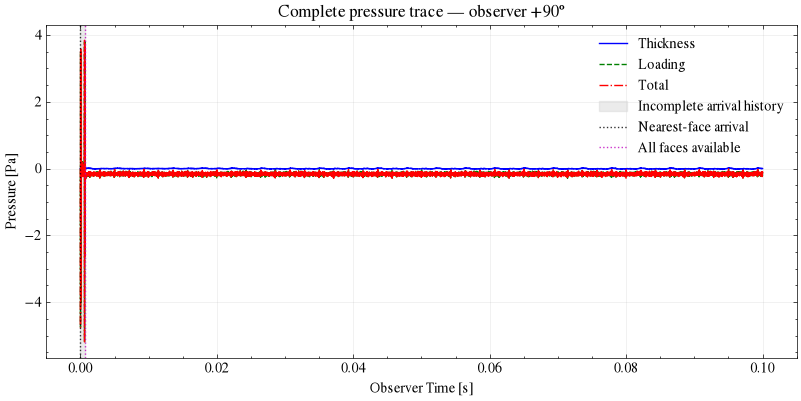

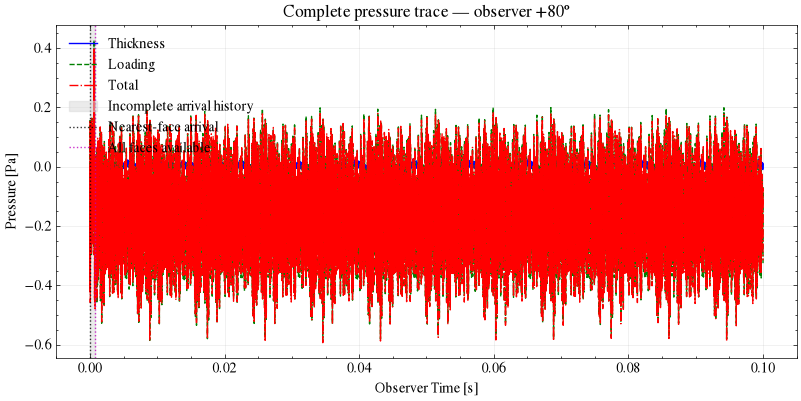

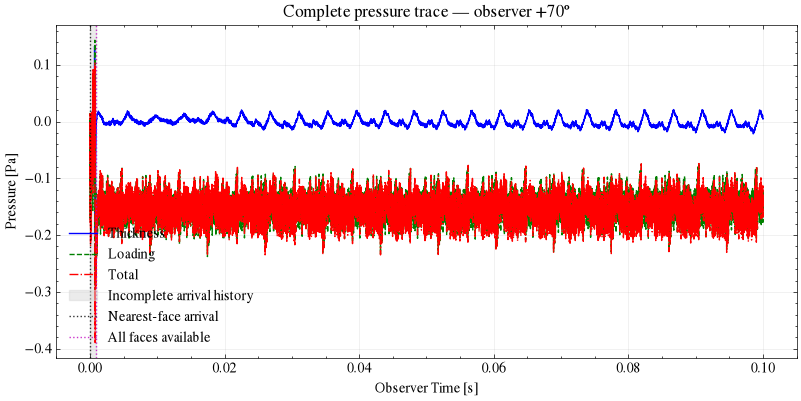

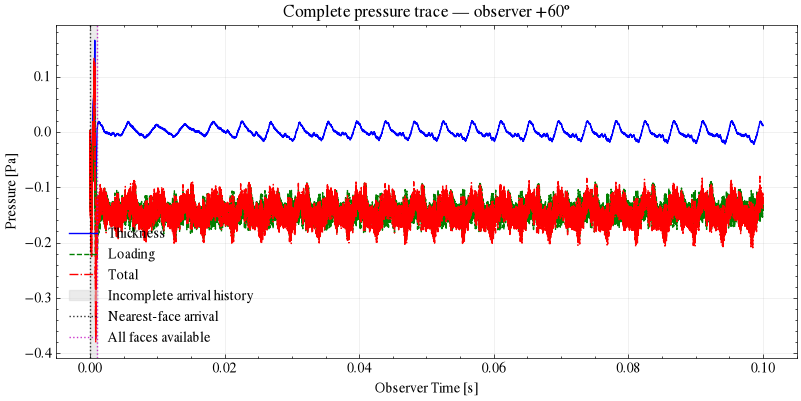

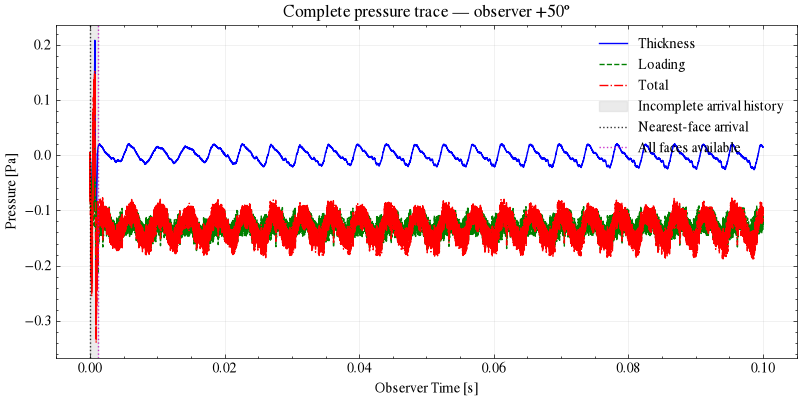

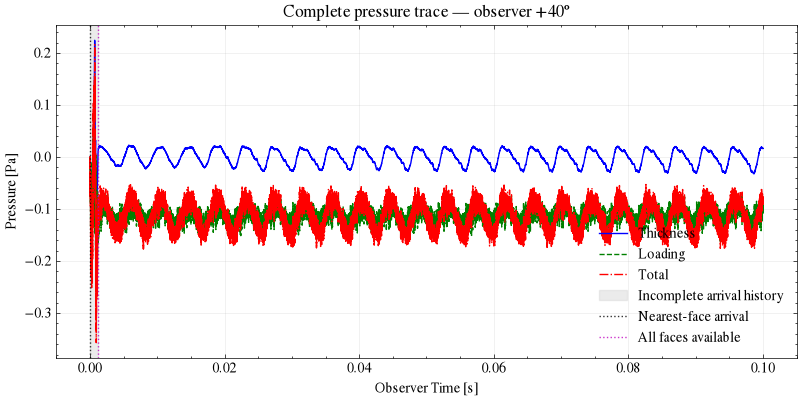

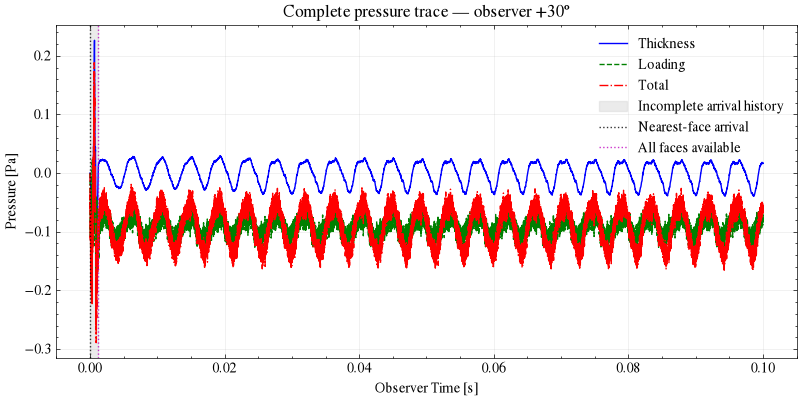

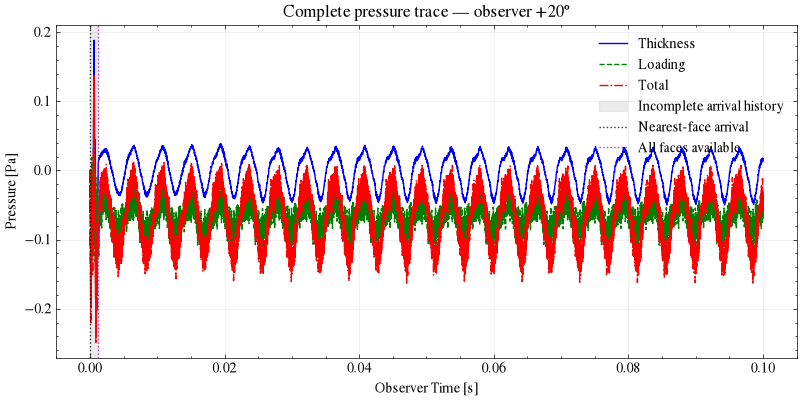

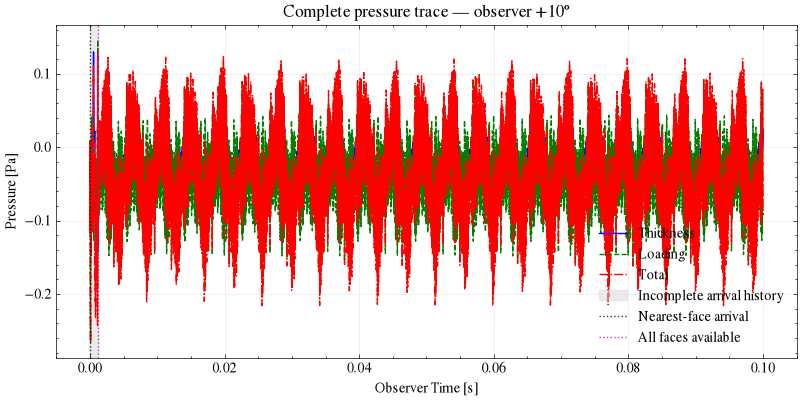

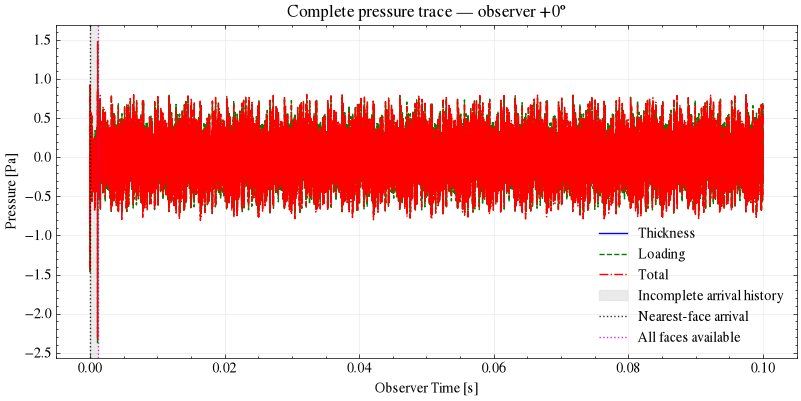

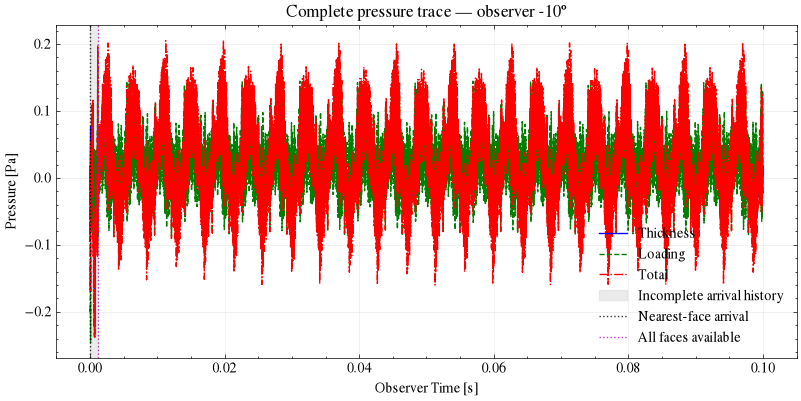

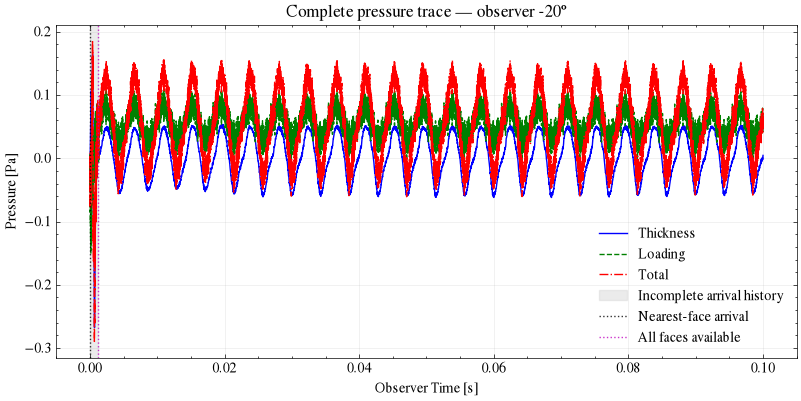

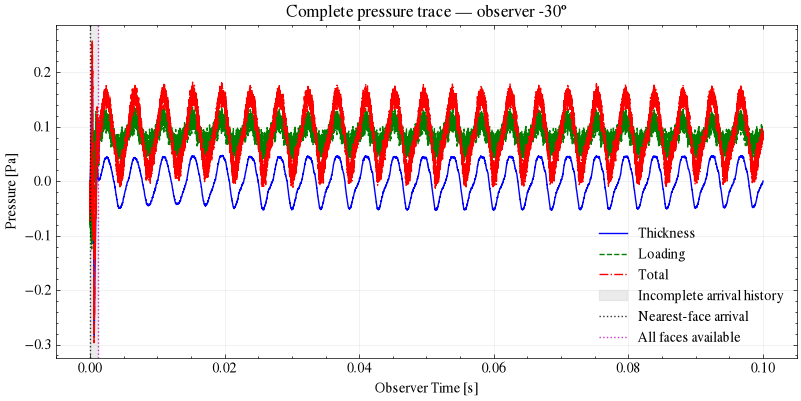

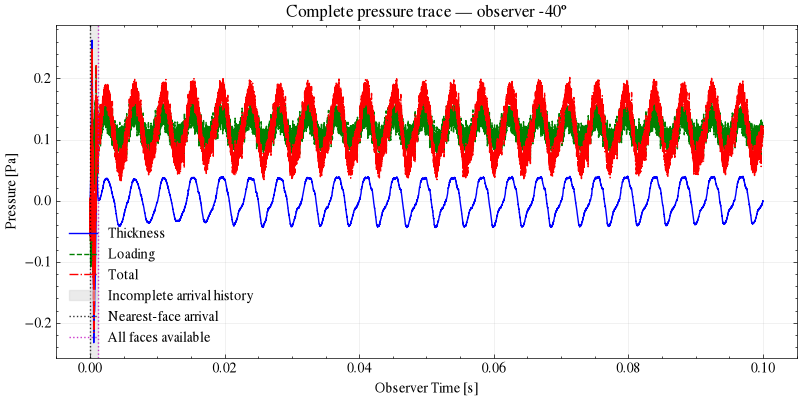

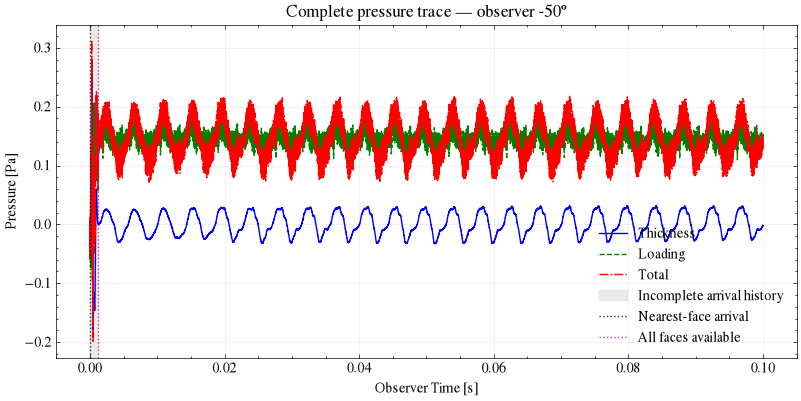

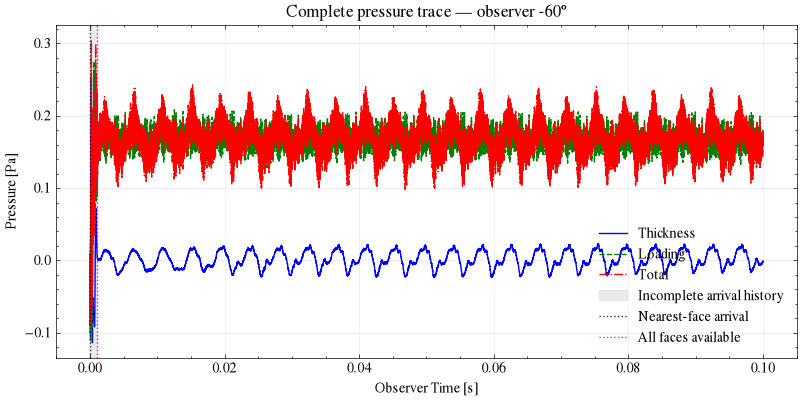

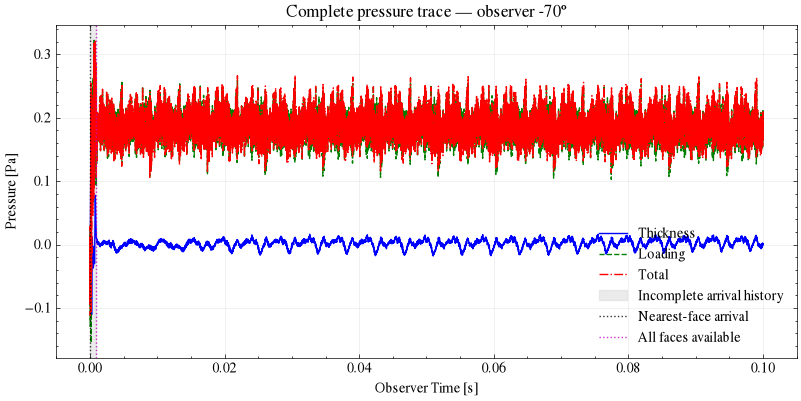

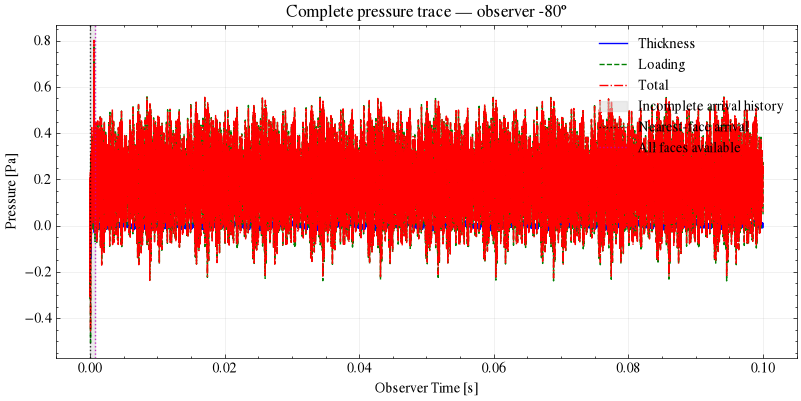

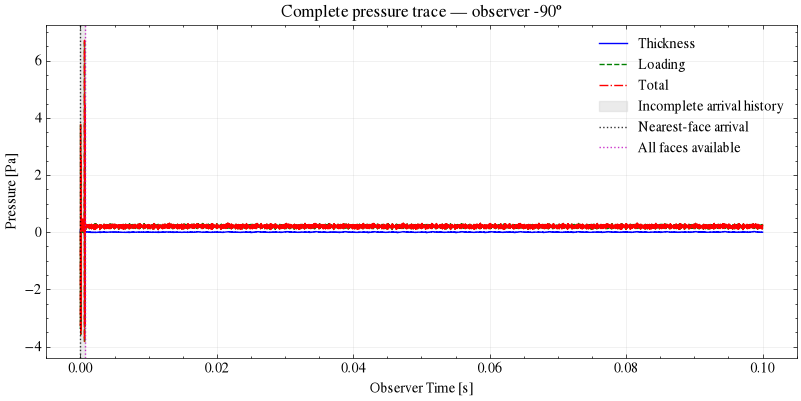

In [6]:
total_pressure_by_observer = result.total_pressure_pa
if total_pressure_by_observer.ndim == 1:
    total_pressure_by_observer = total_pressure_by_observer[None, :]
maximum_delays_s = torch.as_tensor(
    result.maximum_delay_s, device=result.observer_times_s.device
).reshape(-1)
fully_arrived = result.observer_times_s[None, :] >= maximum_delays_s[:, None]
if not torch.all(torch.any(fully_arrived, dim=1)):
    raise RuntimeError(
        "The source record ends before every face can reach every observer."
    )

result_observers_m = (
    result.observer_m if result.observer_m.ndim == 2 else result.observer_m[None, :]
)
result_angles_deg = torch.rad2deg(
    torch.atan2(result_observers_m[:, 1], result_observers_m[:, 0])
)
observer_labels = [f"{float(angle):+g}°" for angle in result_angles_deg.detach().cpu()]
for observer_index, label in enumerate(observer_labels):
    tail_total = total_pressure_by_observer[
        observer_index, fully_arrived[observer_index]
    ]
    tail_rms_pa = float(torch.sqrt(torch.mean((tail_total - tail_total.mean()) ** 2)))
    tail_duration_ms = float(
        (result.observer_times_s[-1] - maximum_delays_s[observer_index]) * 1e3
    )
    print(
        f"Observer {label}: {tail_total.numel():,} fully arrived samples, {tail_duration_ms:.3f} ms, RMS={tail_rms_pa:.6g} Pa"
    )

for observer_index, label in enumerate(observer_labels):
    plot_pressure_history(
        result.for_observer(observer_index),
        annotate_arrivals=True,
        title=f"Complete pressure trace — observer {label}",
    )
    plt.show()

## 4. Check whether the record is long enough for a spectrum

Each spectrum uses a fully arrived tail window containing exactly the requested number of rotor rotations. The duration check below uses the worst-case propagation delay across all configured observers.

In [7]:
requested_rotations = 11
blade_count = 2
rotation_frequency_hz = rpm / 60.0
blade_passing_frequency_hz = blade_count * rotation_frequency_hz
source_duration_s = float(series.source_times_s[-1])
requested_observer_duration_s = requested_rotations / rotation_frequency_hz
worst_maximum_delay_s = float(maximum_delays_s.max())
required_source_duration_s = requested_observer_duration_s + worst_maximum_delay_s
median_time_step_s = torch.median(time_steps_s)
required_frame_count = (
    int(torch.ceil(required_source_duration_s / median_time_step_s)) + 1
)

print(f"Record duration: {source_duration_s:.6f} s")
print(f"Record rotations: {source_duration_s * rotation_frequency_hz:.6f}")
print(f"Record BPF cycles: {source_duration_s * blade_passing_frequency_hz:.6f}")
print(
    f"Shortest fully arrived tail: {(source_duration_s - worst_maximum_delay_s) * rotation_frequency_hz:.6f} rotations"
)
print(
    f"Required duration for {requested_rotations} fully arrived rotations: {required_source_duration_s:.6f} s"
)
print(
    f"Approximate frames required at {median_time_step_s * 1e6:.3f} us cadence: {required_frame_count:,}"
)
print(f"Spectrum ready: {source_duration_s >= required_source_duration_s}")

Record duration: 0.100000 s
Record rotations: 11.666667
Record BPF cycles: 23.333333
Shortest fully arrived tail: 11.519823 rotations
Required duration for 11 fully arrived rotations: 0.095544 s
Approximate frames required at 5.000 us cadence: 19,110
Spectrum ready: True


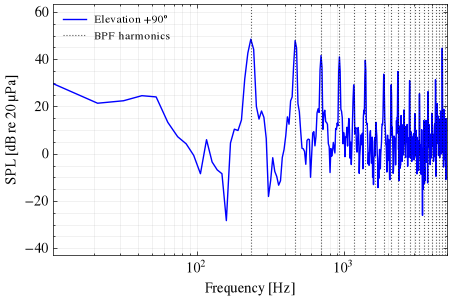

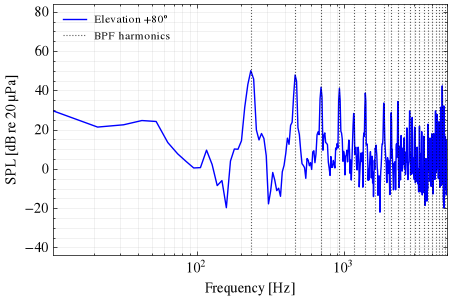

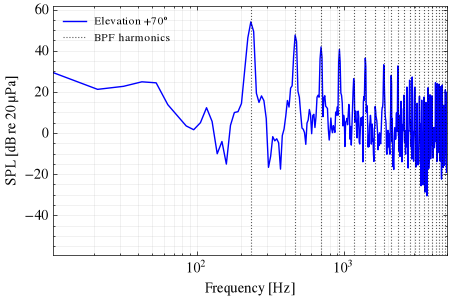

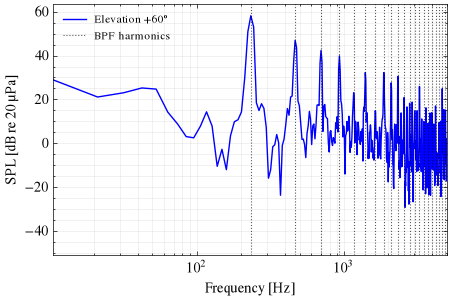

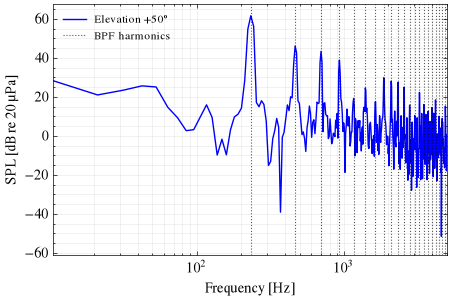

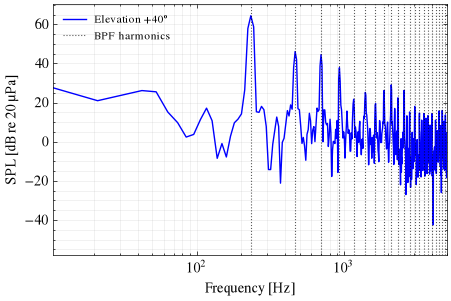

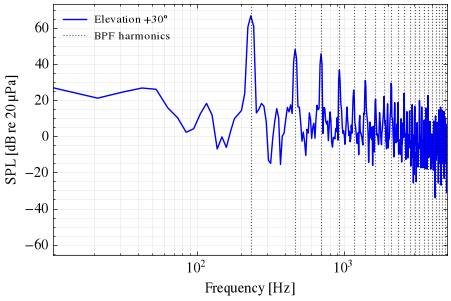

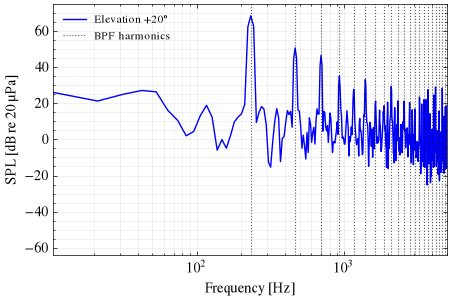

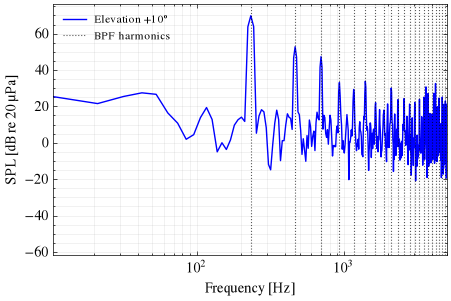

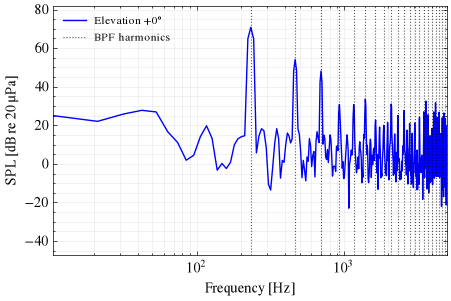

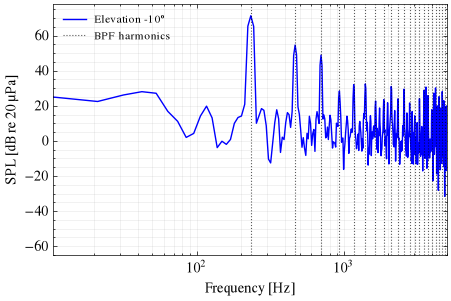

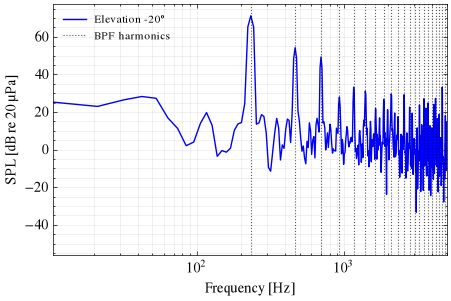

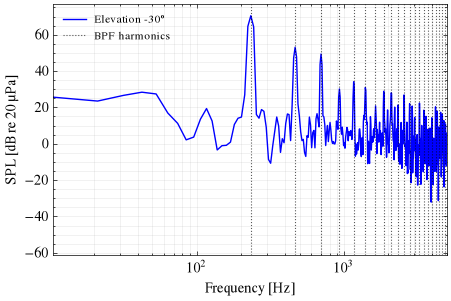

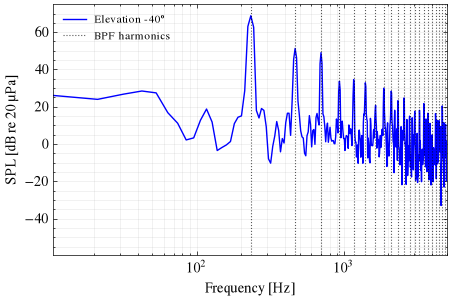

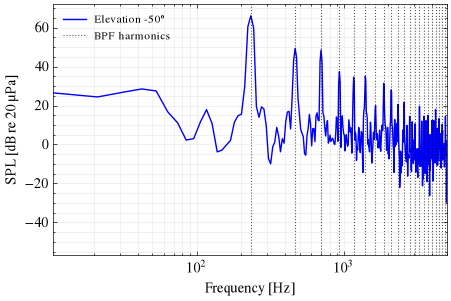

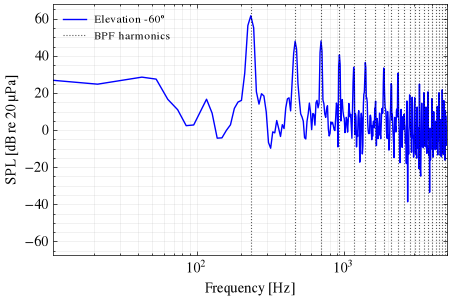

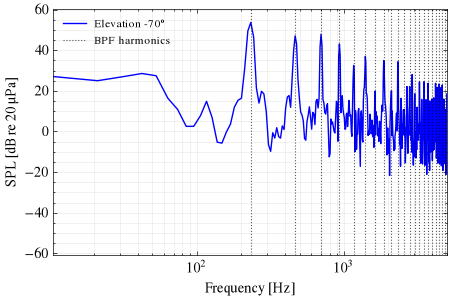

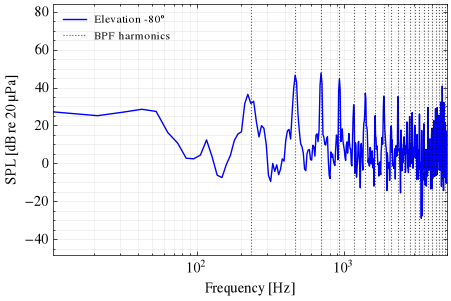

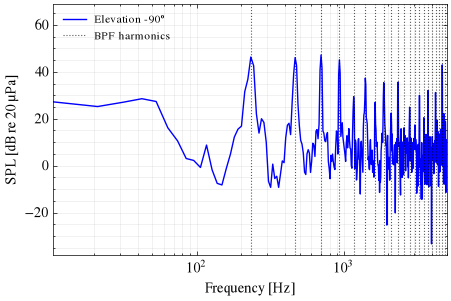

In [8]:
# Single-sided spectra for every observer over the final requested rotations
spectrum_frequency_ceiling_hz = 5000.0
spectrum_plot = plot_spl_spectrum(
    result,
    rotations=requested_rotations,
    blade_count=blade_count,
    xlim_hz=(None, spectrum_frequency_ceiling_hz),
)
frequency_hz = spectrum_plot.frequencies_hz
spl_db = spectrum_plot.spl_db
plt.show()

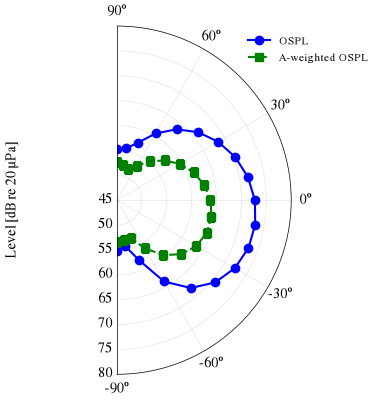

In [9]:
# Overall SPL directivity as a function of observer elevation
oaspl_frequency_ceiling_hz = spectrum_frequency_ceiling_hz
oaspl_db = spl_spectrum_to_oaspl(
    spl_db[:, 1:],
    frequency_hz[1:],  # Exclude the DC bin.
    frequency_ceiling_hz=oaspl_frequency_ceiling_hz,
    dim=1,
)
a_weighted_oaspl_db = spl_spectrum_to_a_weighted_oaspl(
    spl_db[:, 1:],
    frequency_hz[1:],  # Exclude the DC bin.
    frequency_ceiling_hz=oaspl_frequency_ceiling_hz,
    dim=1,
)
plot_oaspl_directivity(
    result_angles_deg,
    oaspl_db,
    a_weighted_oaspl_db=a_weighted_oaspl_db,
)
plt.show()